# Klasifikasi Hate Speech dengan XLM-RoBERTa-base

- Jalankan notebook secara berurutan pada GPU.
- EN, IT, dan NL dilatih bergantian dari model pretrained baru.
- Hasil setiap bahasa disimpan dalam folder dan ZIP terpisah.
- Memori dibersihkan sebelum dan sesudah setiap bahasa.
- Unduh hasil sebelum menghentikan sesi Modal.


## 1. Library dan pengaturan

In [1]:
import os
os.environ.update(USE_TF='0', USE_FLAX='0', TOKENIZERS_PARALLELISM='false')

import gc
import re
import hashlib
import unicodedata
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
from itertools import combinations
from importlib.metadata import version
from zipfile import ZipFile, ZIP_DEFLATED

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import Dataset
from huggingface_hub import HfApi
from IPython.display import display, FileLink
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    Trainer, TrainingArguments, EarlyStoppingCallback, set_seed,
)

LANGUAGES = ['en', 'it', 'nl']
MODEL_NAME = 'FacebookAI/xlm-roberta-base'
SEED = 42
MAX_LENGTH = 384
EPOCHS = 10
PATIENCE = 3
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE = 16
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 0.01
LABELS = ['no', 'yes_implicit', 'yes_explicit']
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = {i: label for label, i in LABEL2ID.items()}

assert LANGUAGES and set(LANGUAGES) <= {'en', 'it', 'nl'}
if not torch.cuda.is_available():
    raise RuntimeError('Gunakan kernel dengan GPU CUDA.')
set_seed(SEED)
print('GPU:', torch.cuda.get_device_name(0))
print('Bahasa:', ', '.join(LANGUAGES))

def cleanup():
    plt.close('all')
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


cleanup()

GPU: NVIDIA H200
Bahasa: en, it, nl


## 2. Baca dan periksa data ketiga bahasa

In [2]:
DATA = {}
DATA_HASHES = {}
for DATA_LANGUAGE in LANGUAGES:
    splits = ('train', 'val', 'test')
    names = [f'{DATA_LANGUAGE}-{split}.csv' for split in splits]
    split_folder = f'{DATA_LANGUAGE}-splitting'
    candidates = [
        Path('.'), Path('data'), Path(split_folder),
        Path('data') / split_folder, Path('Analisis/data') / split_folder,
        Path('../data') / split_folder,
    ]

    for DATA_DIR in candidates:
        present = [(DATA_DIR / name).is_file() for name in names]
        if any(present):
            if not all(present):
                raise FileNotFoundError(f'Lengkapi {names} dalam folder {DATA_DIR.resolve()}.')
            break
    else:
        raise FileNotFoundError(f'Upload {names} ke {Path.cwd()}. Periksa DATA_LANGUAGE.')

    required = {'StereoQueerEval_id', 'yt_comment', 'hate_speech'}
    video_columns = {'yt_title', 'yt_description'}

    frames, source_hashes, audit_keys = {}, {}, {}
    normalize = lambda text: re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', str(text)).casefold()).strip()

    for split, name in zip(splits, names):
        csv_path = DATA_DIR / name
        frame = pd.read_csv(csv_path, dtype=str, keep_default_na=False, encoding='utf-8-sig')

        missing = required - set(frame.columns)
        if missing:
            raise ValueError(f'{name}: kolom wajib tidak tersedia: {sorted(missing)}.')
        if frame.empty:
            raise ValueError(f'{name}: data kosong.')
        for column in ('StereoQueerEval_id', 'yt_comment'):
            if frame[column].str.strip().eq('').any():
                raise ValueError(f'{name}: {column} berisi nilai kosong.')
        if frame['StereoQueerEval_id'].duplicated().any():
            raise ValueError(f'{name}: terdapat ID duplikat.')
        if set(frame['hate_speech']) != set(LABELS):
            raise ValueError(f'{name}: kelas tidak sesuai dengan LABELS.')

        audit_keys[split] = {
            'id': set(frame['StereoQueerEval_id']),
            'comment': set(frame['yt_comment'].map(normalize)),
        }
        if video_columns <= set(frame.columns):
            contexts = zip(frame['yt_title'].map(normalize), frame['yt_description'].map(normalize))
            audit_keys[split]['video'] = {pair for pair in contexts if any(pair)}

        frames[split] = frame
        source_hashes[name] = hashlib.sha256(csv_path.read_bytes()).hexdigest()

    for left, right in combinations(frames, 2):
        shared_keys = audit_keys[left].keys() & audit_keys[right].keys()
        for key in shared_keys:
            if audit_keys[left][key] & audit_keys[right][key]:
                raise ValueError(f'Overlap {key}: {left} dan {right}. Periksa split asli.')

    print('Folder CSV:', DATA_DIR.resolve())
    class_counts = pd.DataFrame({split: frame['hate_speech'].value_counts() for split, frame in frames.items()}).T
    display(class_counts)
    DATA[DATA_LANGUAGE] = frames
    DATA_HASHES[DATA_LANGUAGE] = source_hashes

Folder CSV: /__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/data/en-splitting


hate_speech,no,yes_explicit,yes_implicit
train,983,582,546
val,147,75,70
test,277,153,156


Folder CSV: /__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/data/it-splitting


hate_speech,no,yes_explicit,yes_implicit
train,822,476,401
val,105,59,56
test,233,124,124


Folder CSV: /__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/data/nl-splitting


hate_speech,no,yes_explicit,yes_implicit
train,784,437,335
val,109,62,55
test,234,125,97


## 3. Siapkan perhitungan loss dan metrik

In [3]:
def compute_loss(outputs, labels, num_items_in_batch=None):
    return torch.nn.functional.cross_entropy(
        outputs.logits.float(), labels, weight=class_weights.to(outputs.logits.device),
    )

def compute_metrics(prediction):
    logits = prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    predicted = np.asarray(logits).argmax(axis=-1)
    actual = prediction.label_ids
    return {
        'macro_f1': float(f1_score(actual, predicted, labels=range(len(LABELS)), average='macro', zero_division=0)),
        'accuracy': float(accuracy_score(actual, predicted)),
        'weighted_f1': float(f1_score(actual, predicted, labels=range(len(LABELS)), average='weighted', zero_division=0)),
    }

## 4. Pelatihan dan evaluasi ketiga bahasa

- Jalankan bagian English, Italian, lalu Dutch secara berurutan.
- Setiap bahasa dimulai dari model pretrained baru.
- Checkpoint dipilih berdasarkan macro-F1 validation.
- Hasil dan ZIP disimpan terpisah untuk setiap bahasa.
- Memori dibersihkan pada awal dan akhir setiap bagian bahasa.

Pelatihan maksimal 10 epoch dengan early stopping 3 evaluasi. ZIP hanya memuat laporan CSV dan PNG; checkpoint terbaik tetap berada di folder run masing-masing.


In [ ]:
MODEL_COMMIT = HfApi().model_info(MODEL_NAME).sha
summaries = []

### 4.1. English


Bahasa: en | Hasil: results/xlm_roberta_base_data-en_20261026T175022Z_fa4b09a8


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Macro-F1 validation terbaik: 0.5881013872553761


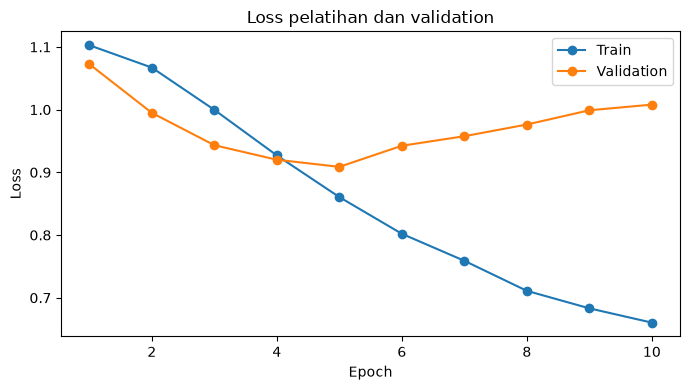

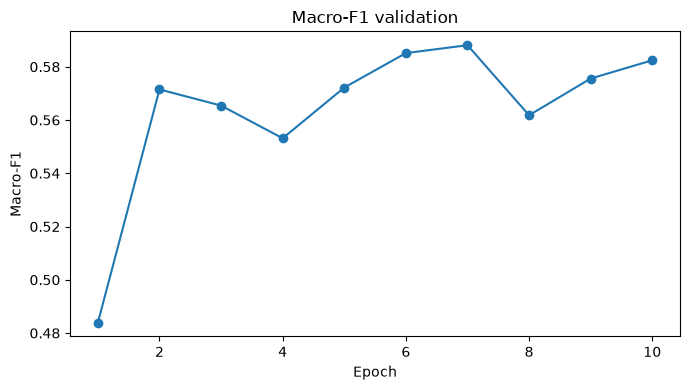

VAL {'macro_f1': 0.5881013872553761, 'accuracy': 0.613013698630137, 'weighted_f1': 0.618252803088652, 'loss': 0.9576238393783569}


,precision,recall,f1-score,support
no,0.716312,0.687075,0.701389,147.000000
yes_implicit,0.413793,0.514286,0.458599,70.000000
yes_explicit,0.656250,0.560000,0.604317,75.000000
accuracy,0.613014,0.613014,0.613014,0.613014
macro avg,0.595452,0.587120,0.588101,292.000000
weighted avg,0.628363,0.613014,0.618253,292.000000


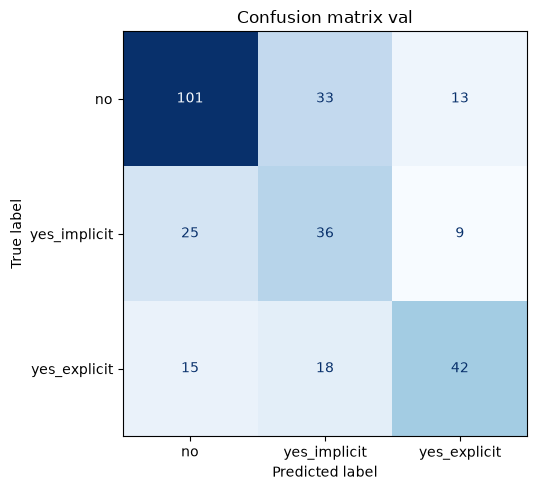

TEST {'macro_f1': 0.5290521499151968, 'accuracy': 0.552901023890785, 'weighted_f1': 0.555484227945985, 'loss': 1.018288016319275}


,precision,recall,f1-score,support
no,0.667910,0.646209,0.656881,277.000000
yes_implicit,0.389535,0.429487,0.408537,156.000000
yes_explicit,0.534247,0.509804,0.521739,153.000000
accuracy,0.552901,0.552901,0.552901,0.552901
macro avg,0.530564,0.528500,0.529052,586.000000
weighted avg,0.558905,0.552901,0.555484,586.000000


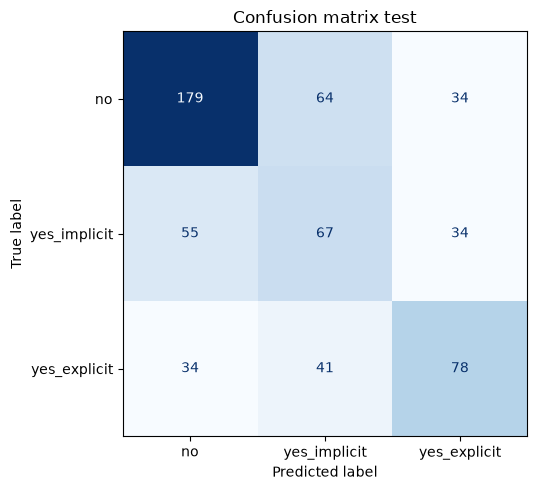

Hasil dan ZIP tersimpan di Volume ptm-qwen.
ZIP: /__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/results/xlm_roberta_base_data-en_20261026T175022Z_fa4b09a8.zip
Jalankan di PowerShell lokal untuk download:
$RunName = "xlm_roberta_base_data-en_20261026T175022Z_fa4b09a8"
python -X utf8 -m modal volume get ptm-qwen "/results/$RunName.zip" "./Analisis/results/$RunName.zip"
Expand-Archive -LiteralPath "./Analisis/results/$RunName.zip" -DestinationPath "./Analisis/results/modal-xlm-roberta"


/__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/results/xlm_roberta_base_data-en_20261026T175022Z_fa4b09a8.zip

In [ ]:
DATA_LANGUAGE = 'en'
cleanup()
trainer = model = tokenizer = datasets = class_weights = prediction = logits = None
set_seed(SEED)
frames = DATA[DATA_LANGUAGE]
source_hashes = DATA_HASHES[DATA_LANGUAGE]
OUT = Path('results') / f'xlm_roberta_base_data-{DATA_LANGUAGE}_{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{uuid4().hex[:8]}'
OUT.mkdir(parents=True, exist_ok=False)
print('Bahasa:', DATA_LANGUAGE, '| Hasil:', OUT)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_COMMIT, use_fast=True)
datasets = {}
for split, frame in frames.items():
    tokens = tokenizer(frame['yt_comment'].tolist(), max_length=MAX_LENGTH, truncation=True)
    tokens['labels'] = frame['hate_speech'].map(LABEL2ID).tolist()
    datasets[split] = Dataset.from_dict(tokens)

class_counts = frames['train']['hate_speech'].value_counts().reindex(LABELS)
class_weights = torch.tensor(len(frames['train']) / (len(LABELS) * class_counts.to_numpy()), dtype=torch.float32)
print('Bobot kelas:', dict(zip(LABELS, class_weights.tolist())))

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, revision=MODEL_COMMIT, num_labels=len(LABELS),
    label2id=LABEL2ID, id2label=ID2LABEL,
)
model.config.use_cache = False

args = TrainingArguments(
    output_dir=str(OUT / 'checkpoints'), num_train_epochs=EPOCHS,
    per_device_train_batch_size=TRAIN_BATCH_SIZE, per_device_eval_batch_size=EVAL_BATCH_SIZE,
    learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
    warmup_steps=0, lr_scheduler_type='linear', optim='adamw_torch',
    gradient_accumulation_steps=1, gradient_checkpointing=True,
    gradient_checkpointing_kwargs={'use_reentrant': False}, eval_accumulation_steps=1,
    fp16=True, bf16=False, seed=SEED, data_seed=SEED,
    eval_strategy='epoch', logging_strategy='epoch', save_strategy='best',
    load_best_model_at_end=True, metric_for_best_model='macro_f1', greater_is_better=True,
    save_total_limit=1, save_only_model=True,
    report_to='none', disable_tqdm=False,
)
trainer = Trainer(
    model=model, args=args, train_dataset=datasets['train'], eval_dataset=datasets['val'],
    processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics, compute_loss_func=compute_loss,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
)
trainer.model_accepts_loss_kwargs = False
train_result = trainer.train()
print('Macro-F1 validation terbaik:', trainer.state.best_metric)

history = pd.DataFrame(trainer.state.log_history)
history.to_csv(OUT / 'training_log.csv', index=False)

train_history = history.dropna(subset=['loss'])
val_history = history.dropna(subset=['eval_loss'])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(train_history['epoch'], train_history['loss'], marker='o', label='Train')
ax.plot(val_history['epoch'], val_history['eval_loss'], marker='o', label='Validation')
ax.set(xlabel='Epoch', ylabel='Loss', title='Loss pelatihan dan validation')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'training_loss.png', dpi=160)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(val_history['epoch'], val_history['eval_macro_f1'], marker='o')
ax.set(xlabel='Epoch', ylabel='Macro-F1', title='Macro-F1 validation')
fig.tight_layout()
fig.savefig(OUT / 'validation_macro_f1.png', dpi=160)
plt.show()
plt.close(fig)

results = {}
for split in ('val', 'test'):
    prediction = trainer.predict(datasets[split], metric_key_prefix=split)
    logits = prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    predicted = np.asarray(logits).argmax(axis=-1)
    actual = prediction.label_ids
    results[split] = compute_metrics(prediction)
    results[split]['loss'] = float(prediction.metrics[f'{split}_loss'])

    report = pd.DataFrame(classification_report(
        actual, predicted, labels=range(len(LABELS)), target_names=LABELS,
        output_dict=True, zero_division=0,
    )).T
    report.to_csv(OUT / f'{split}_report.csv')
    print(split.upper(), results[split])
    display(report)

    predictions = frames[split][['StereoQueerEval_id', 'yt_comment', 'hate_speech']].copy()
    predictions['predicted_label'] = [ID2LABEL[int(i)] for i in predicted]
    predictions['correct'] = predictions['hate_speech'] == predictions['predicted_label']
    predictions.to_csv(OUT / f'{split}_prediction.csv', index=False)

    fig, ax = plt.subplots(figsize=(7, 5))
    matrix = ConfusionMatrixDisplay.from_predictions(
        actual, predicted, labels=range(len(LABELS)), display_labels=LABELS,
        cmap='Blues', colorbar=False, ax=ax,
    )
    ax.set_title(f'Confusion matrix {split}')
    fig.tight_layout()
    fig.savefig(OUT / f'{split}_confusion_matrix.png', dpi=160)
    pd.DataFrame(matrix.confusion_matrix, index=LABELS, columns=LABELS).to_csv(
        OUT / f'{split}_confusion_matrix.csv', index_label='actual_label',
    )
    plt.show()
    plt.close(fig)
    del prediction, logits, predicted, actual, predictions, matrix
    cleanup()

# Simpan dan unduh hasil
config = {
    'model': MODEL_NAME, 'revision': MODEL_COMMIT, 'data_language': DATA_LANGUAGE,
    'input': 'yt_comment', 'preprocessing': 'raw', 'labels': LABELS,
    'label_to_id': LABEL2ID, 'max_length': MAX_LENGTH, 'seed': SEED,
    'loss': 'weighted_cross_entropy', 'class_weights': dict(zip(LABELS, class_weights.tolist())),
    'training': args.to_dict(), 'early_stopping_patience': PATIENCE,
    'best_validation_macro_f1': trainer.state.best_metric,
    'best_model_checkpoint': trainer.state.best_model_checkpoint,
    'train_metrics': train_result.metrics, 'csv_sha256': source_hashes,
    'versions': {name: version(name) for name in ('torch', 'transformers', 'accelerate', 'datasets')},
    'model_exported': False,
}
config_rows = []
for key, value in config.items():
    if isinstance(value, dict):
        config_rows.extend({'parameter': f'{key}.{name}', 'value': item} for name, item in value.items())
    else:
        config_rows.append({'parameter': key, 'value': value})
pd.DataFrame(config_rows).to_csv(OUT / 'config.csv', index=False)
pd.DataFrame(results).T.to_csv(OUT / 'metrics.csv')

required_reports = ['config.csv', 'metrics.csv', 'training_log.csv',
                    'training_loss.png', 'validation_macro_f1.png']
required_reports += [f'{split}_{suffix}' for split in ('val', 'test')
                     for suffix in ('report.csv', 'prediction.csv',
                                    'confusion_matrix.csv', 'confusion_matrix.png')]
missing = [name for name in required_reports if not (OUT / name).is_file() or not (OUT / name).stat().st_size]
if missing:
    raise RuntimeError(f'Laporan belum lengkap: {missing}')
zip_path = OUT.with_suffix('.zip')
with ZipFile(zip_path, 'w', compression=ZIP_DEFLATED) as archive:
    for file in OUT.rglob('*'):
        if file.is_file() and file.suffix.lower() in {'.csv', '.png'} and file.relative_to(OUT).parts[0] != 'checkpoints':
            archive.write(file, file.relative_to(OUT.parent))
with ZipFile(zip_path) as archive:
    assert archive.testzip() is None
    assert {f'{OUT.name}/{name}' for name in required_reports} <= set(archive.namelist())

if OUT.resolve().is_relative_to(Path('/workspace').resolve()):
    import modal
    modal.Volume.from_name('ptm-qwen').commit()
    print('Hasil dan ZIP tersimpan di Volume ptm-qwen.')


summaries.append({'language': DATA_LANGUAGE, 'validation_macro_f1': results['val']['macro_f1'],
                  'test_macro_f1': results['test']['macro_f1'], 'output': str(OUT)})
trainer = model = tokenizer = datasets = class_weights = prediction = logits = None
tokens = None
cleanup()

### 4.2. Italian


Bahasa: it | Hasil: results/xlm_roberta_base_data-it_20261026T175209Z_bc72a4c8
Bobot kelas: {'no': 0.6889699697494507, 'yes_implicit': 1.4123026132583618, 'yes_explicit': 1.1897759437561035}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[RANK 0] Detected kernel version 4.19.0, which is below the recommended minimum of 

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy,Weighted F1
1,1.106300,1.099967,0.215385,0.477273,0.308392
2,1.081263,1.061265,0.398575,0.472727,0.451152
3,1.016990,1.003482,0.467596,0.513636,0.508602
4,0.932038,1.006916,0.502502,0.545455,0.540443
5,0.869643,1.017960,0.515862,0.559091,0.554199
6,0.812804,1.020035,0.551600,0.604545,0.588792
7,0.764665,1.028182,0.561913,0.600000,0.595639
8,0.718434,1.060299,0.542741,0.590909,0.581219
9,0.707033,1.085616,0.547598,0.595455,0.582876
10,0.673188,1.076560,0.539515,0.581818,0.575198


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Macro-F1 validation terbaik: 0.5619132802199724


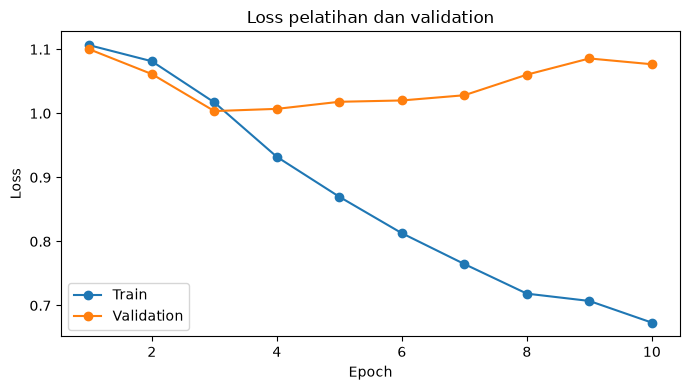

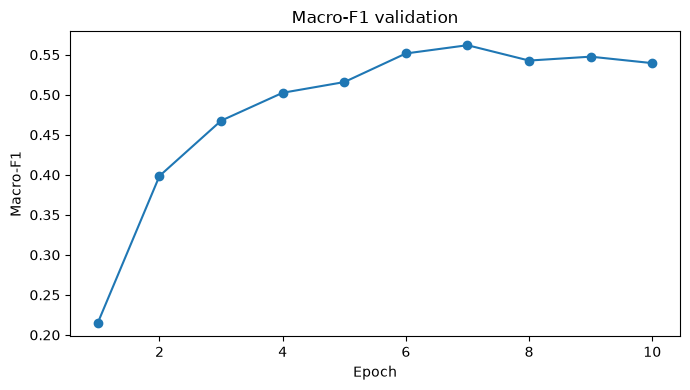

VAL {'macro_f1': 0.5619132802199724, 'accuracy': 0.6, 'weighted_f1': 0.595639312643345, 'loss': 1.0281819105148315}


,precision,recall,f1-score,support
no,0.734694,0.685714,0.709360,105.0
yes_implicit,0.382979,0.321429,0.349515,56.0
yes_explicit,0.560000,0.711864,0.626866,59.0
accuracy,0.600000,0.600000,0.600000,0.6
macro avg,0.559224,0.573002,0.561913,220.0
weighted avg,0.598317,0.600000,0.595639,220.0


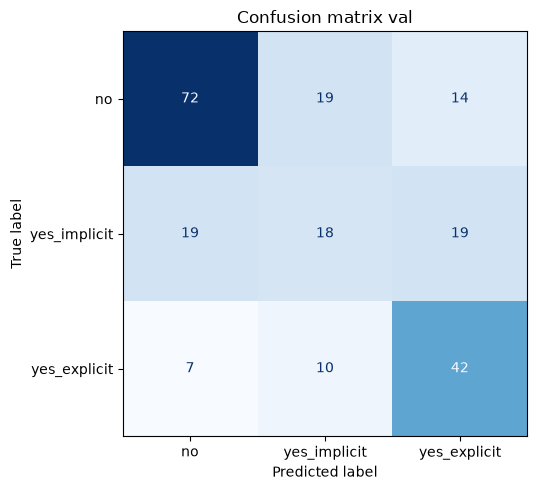

TEST {'macro_f1': 0.5745152511257137, 'accuracy': 0.6029106029106029, 'weighted_f1': 0.6042268052644187, 'loss': 0.9852244257926941}


,precision,recall,f1-score,support
no,0.711790,0.699571,0.705628,233.000000
yes_implicit,0.458647,0.491935,0.474708,124.000000
yes_explicit,0.554622,0.532258,0.543210,124.000000
accuracy,0.602911,0.602911,0.602911,0.602911
macro avg,0.575020,0.574588,0.574515,481.000000
weighted avg,0.606013,0.602911,0.604227,481.000000


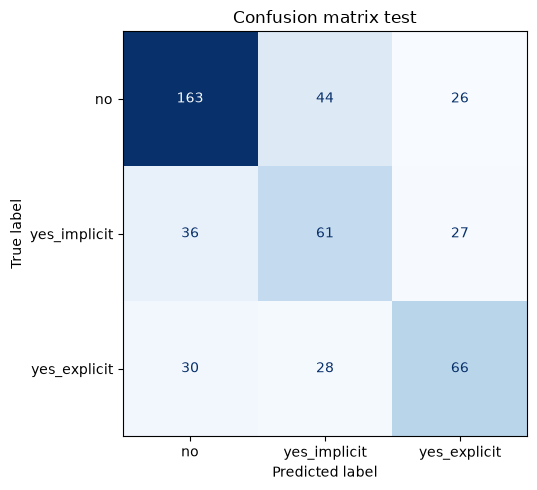

Hasil dan ZIP tersimpan di Volume ptm-qwen.
ZIP: /__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/results/xlm_roberta_base_data-it_20261026T175209Z_bc72a4c8.zip
Jalankan di PowerShell lokal untuk download:
$RunName = "xlm_roberta_base_data-it_20261026T175209Z_bc72a4c8"
python -X utf8 -m modal volume get ptm-qwen "/results/$RunName.zip" "./Analisis/results/$RunName.zip"
Expand-Archive -LiteralPath "./Analisis/results/$RunName.zip" -DestinationPath "./Analisis/results/modal-xlm-roberta"


/__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/results/xlm_roberta_base_data-it_20261026T175209Z_bc72a4c8.zip

In [ ]:
DATA_LANGUAGE = 'it'
cleanup()
trainer = model = tokenizer = datasets = class_weights = prediction = logits = None
set_seed(SEED)
frames = DATA[DATA_LANGUAGE]
source_hashes = DATA_HASHES[DATA_LANGUAGE]
OUT = Path('results') / f'xlm_roberta_base_data-{DATA_LANGUAGE}_{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{uuid4().hex[:8]}'
OUT.mkdir(parents=True, exist_ok=False)
print('Bahasa:', DATA_LANGUAGE, '| Hasil:', OUT)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_COMMIT, use_fast=True)
datasets = {}
for split, frame in frames.items():
    tokens = tokenizer(frame['yt_comment'].tolist(), max_length=MAX_LENGTH, truncation=True)
    tokens['labels'] = frame['hate_speech'].map(LABEL2ID).tolist()
    datasets[split] = Dataset.from_dict(tokens)

class_counts = frames['train']['hate_speech'].value_counts().reindex(LABELS)
class_weights = torch.tensor(len(frames['train']) / (len(LABELS) * class_counts.to_numpy()), dtype=torch.float32)
print('Bobot kelas:', dict(zip(LABELS, class_weights.tolist())))

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, revision=MODEL_COMMIT, num_labels=len(LABELS),
    label2id=LABEL2ID, id2label=ID2LABEL,
)
model.config.use_cache = False

args = TrainingArguments(
    output_dir=str(OUT / 'checkpoints'), num_train_epochs=EPOCHS,
    per_device_train_batch_size=TRAIN_BATCH_SIZE, per_device_eval_batch_size=EVAL_BATCH_SIZE,
    learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
    warmup_steps=0, lr_scheduler_type='linear', optim='adamw_torch',
    gradient_accumulation_steps=1, gradient_checkpointing=True,
    gradient_checkpointing_kwargs={'use_reentrant': False}, eval_accumulation_steps=1,
    fp16=True, bf16=False, seed=SEED, data_seed=SEED,
    eval_strategy='epoch', logging_strategy='epoch', save_strategy='best',
    load_best_model_at_end=True, metric_for_best_model='macro_f1', greater_is_better=True,
    save_total_limit=1, save_only_model=True,
    report_to='none', disable_tqdm=False,
)
trainer = Trainer(
    model=model, args=args, train_dataset=datasets['train'], eval_dataset=datasets['val'],
    processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics, compute_loss_func=compute_loss,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
)
trainer.model_accepts_loss_kwargs = False
train_result = trainer.train()
print('Macro-F1 validation terbaik:', trainer.state.best_metric)

history = pd.DataFrame(trainer.state.log_history)
history.to_csv(OUT / 'training_log.csv', index=False)

train_history = history.dropna(subset=['loss'])
val_history = history.dropna(subset=['eval_loss'])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(train_history['epoch'], train_history['loss'], marker='o', label='Train')
ax.plot(val_history['epoch'], val_history['eval_loss'], marker='o', label='Validation')
ax.set(xlabel='Epoch', ylabel='Loss', title='Loss pelatihan dan validation')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'training_loss.png', dpi=160)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(val_history['epoch'], val_history['eval_macro_f1'], marker='o')
ax.set(xlabel='Epoch', ylabel='Macro-F1', title='Macro-F1 validation')
fig.tight_layout()
fig.savefig(OUT / 'validation_macro_f1.png', dpi=160)
plt.show()
plt.close(fig)

results = {}
for split in ('val', 'test'):
    prediction = trainer.predict(datasets[split], metric_key_prefix=split)
    logits = prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    predicted = np.asarray(logits).argmax(axis=-1)
    actual = prediction.label_ids
    results[split] = compute_metrics(prediction)
    results[split]['loss'] = float(prediction.metrics[f'{split}_loss'])

    report = pd.DataFrame(classification_report(
        actual, predicted, labels=range(len(LABELS)), target_names=LABELS,
        output_dict=True, zero_division=0,
    )).T
    report.to_csv(OUT / f'{split}_report.csv')
    print(split.upper(), results[split])
    display(report)

    predictions = frames[split][['StereoQueerEval_id', 'yt_comment', 'hate_speech']].copy()
    predictions['predicted_label'] = [ID2LABEL[int(i)] for i in predicted]
    predictions['correct'] = predictions['hate_speech'] == predictions['predicted_label']
    predictions.to_csv(OUT / f'{split}_prediction.csv', index=False)

    fig, ax = plt.subplots(figsize=(7, 5))
    matrix = ConfusionMatrixDisplay.from_predictions(
        actual, predicted, labels=range(len(LABELS)), display_labels=LABELS,
        cmap='Blues', colorbar=False, ax=ax,
    )
    ax.set_title(f'Confusion matrix {split}')
    fig.tight_layout()
    fig.savefig(OUT / f'{split}_confusion_matrix.png', dpi=160)
    pd.DataFrame(matrix.confusion_matrix, index=LABELS, columns=LABELS).to_csv(
        OUT / f'{split}_confusion_matrix.csv', index_label='actual_label',
    )
    plt.show()
    plt.close(fig)
    del prediction, logits, predicted, actual, predictions, matrix
    cleanup()

config = {
    'model': MODEL_NAME, 'revision': MODEL_COMMIT, 'data_language': DATA_LANGUAGE,
    'input': 'yt_comment', 'preprocessing': 'raw', 'labels': LABELS,
    'label_to_id': LABEL2ID, 'max_length': MAX_LENGTH, 'seed': SEED,
    'loss': 'weighted_cross_entropy', 'class_weights': dict(zip(LABELS, class_weights.tolist())),
    'training': args.to_dict(), 'early_stopping_patience': PATIENCE,
    'best_validation_macro_f1': trainer.state.best_metric,
    'best_model_checkpoint': trainer.state.best_model_checkpoint,
    'train_metrics': train_result.metrics, 'csv_sha256': source_hashes,
    'versions': {name: version(name) for name in ('torch', 'transformers', 'accelerate', 'datasets')},
    'model_exported': False,
}
config_rows = []
for key, value in config.items():
    if isinstance(value, dict):
        config_rows.extend({'parameter': f'{key}.{name}', 'value': item} for name, item in value.items())
    else:
        config_rows.append({'parameter': key, 'value': value})
pd.DataFrame(config_rows).to_csv(OUT / 'config.csv', index=False)
pd.DataFrame(results).T.to_csv(OUT / 'metrics.csv')

required_reports = ['config.csv', 'metrics.csv', 'training_log.csv',
                    'training_loss.png', 'validation_macro_f1.png']
required_reports += [f'{split}_{suffix}' for split in ('val', 'test')
                     for suffix in ('report.csv', 'prediction.csv',
                                    'confusion_matrix.csv', 'confusion_matrix.png')]
missing = [name for name in required_reports if not (OUT / name).is_file() or not (OUT / name).stat().st_size]
if missing:
    raise RuntimeError(f'Laporan belum lengkap: {missing}')
zip_path = OUT.with_suffix('.zip')
with ZipFile(zip_path, 'w', compression=ZIP_DEFLATED) as archive:
    for file in OUT.rglob('*'):
        if file.is_file() and file.suffix.lower() in {'.csv', '.png'} and file.relative_to(OUT).parts[0] != 'checkpoints':
            archive.write(file, file.relative_to(OUT.parent))
with ZipFile(zip_path) as archive:
    assert archive.testzip() is None
    assert {f'{OUT.name}/{name}' for name in required_reports} <= set(archive.namelist())

if OUT.resolve().is_relative_to(Path('/workspace').resolve()):
    import modal
    modal.Volume.from_name('ptm-qwen').commit()
    print('Hasil dan ZIP tersimpan di Volume ptm-qwen.')


summaries.append({'language': DATA_LANGUAGE, 'validation_macro_f1': results['val']['macro_f1'],
                  'test_macro_f1': results['test']['macro_f1'], 'output': str(OUT)})
trainer = model = tokenizer = datasets = class_weights = prediction = logits = None
tokens = None
cleanup()

### 4.3. Dutch


Bahasa: nl | Hasil: results/xlm_roberta_base_data-nl_20261026T175333Z_13a5f164
Bobot kelas: {'no': 0.6615646481513977, 'yes_implicit': 1.548258662223816, 'yes_explicit': 1.1868802309036255}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[RANK 0] Detected kernel version 4.19.0, which is below the recommended minimum of 

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy,Weighted F1
1,1.100970,1.091753,0.250743,0.491150,0.341813
2,1.053461,1.057920,0.466354,0.517699,0.508962
3,0.986169,1.089043,0.484017,0.557522,0.532859
4,0.925990,1.032234,0.508127,0.539823,0.541265
5,0.873741,1.081331,0.510927,0.544248,0.545756
6,0.840652,1.125538,0.508302,0.548673,0.545627
7,0.790850,1.195469,0.499550,0.539823,0.536752
8,0.765159,1.241775,0.479816,0.535398,0.523970


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Macro-F1 validation terbaik: 0.5109272074385864


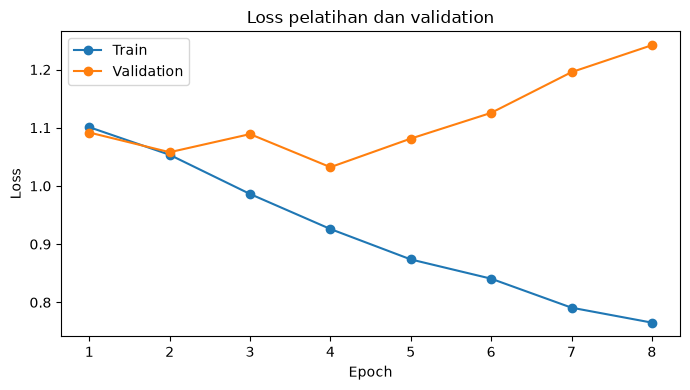

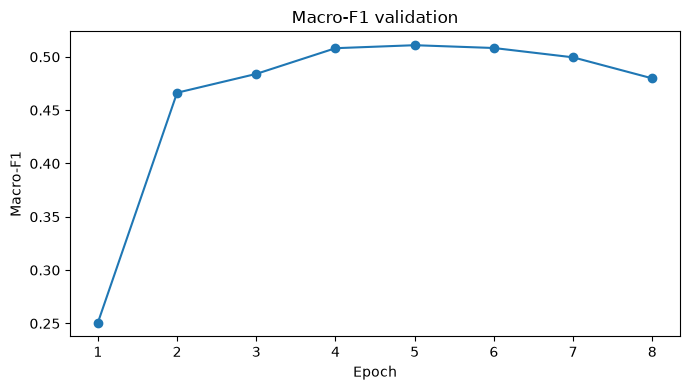

VAL {'macro_f1': 0.5109272074385864, 'accuracy': 0.5442477876106194, 'weighted_f1': 0.5457560699050015, 'loss': 1.0813305377960205}


,precision,recall,f1-score,support
no,0.676190,0.651376,0.663551,109.000000
yes_implicit,0.423077,0.400000,0.411215,55.000000
yes_explicit,0.434783,0.483871,0.458015,62.000000
accuracy,0.544248,0.544248,0.544248,0.544248
macro avg,0.511350,0.511749,0.510927,226.000000
weighted avg,0.548365,0.544248,0.545756,226.000000


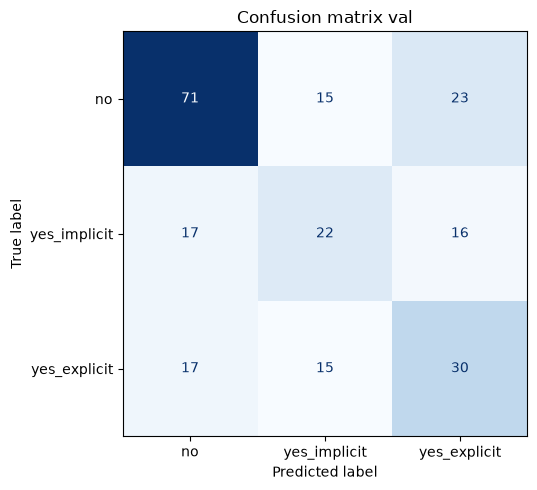

TEST {'macro_f1': 0.5076776549154826, 'accuracy': 0.5482456140350878, 'weighted_f1': 0.5583602339050915, 'loss': 1.0027964115142822}


,precision,recall,f1-score,support
no,0.710900,0.641026,0.674157,234.000000
yes_implicit,0.291339,0.381443,0.330357,97.000000
yes_explicit,0.533898,0.504000,0.518519,125.000000
accuracy,0.548246,0.548246,0.548246,0.548246
macro avg,0.512046,0.508823,0.507678,456.000000
weighted avg,0.573131,0.548246,0.558360,456.000000


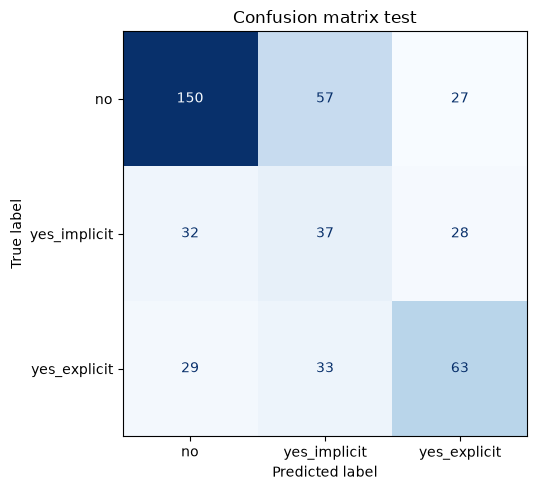

Hasil dan ZIP tersimpan di Volume ptm-qwen.
ZIP: /__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/results/xlm_roberta_base_data-nl_20261026T175333Z_13a5f164.zip
Jalankan di PowerShell lokal untuk download:
$RunName = "xlm_roberta_base_data-nl_20261026T175333Z_13a5f164"
python -X utf8 -m modal volume get ptm-qwen "/results/$RunName.zip" "./Analisis/results/$RunName.zip"
Expand-Archive -LiteralPath "./Analisis/results/$RunName.zip" -DestinationPath "./Analisis/results/modal-xlm-roberta"


/__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/results/xlm_roberta_base_data-nl_20261026T175333Z_13a5f164.zip

In [ ]:
DATA_LANGUAGE = 'nl'
cleanup()
trainer = model = tokenizer = datasets = class_weights = prediction = logits = None
set_seed(SEED)
frames = DATA[DATA_LANGUAGE]
source_hashes = DATA_HASHES[DATA_LANGUAGE]
OUT = Path('results') / f'xlm_roberta_base_data-{DATA_LANGUAGE}_{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{uuid4().hex[:8]}'
OUT.mkdir(parents=True, exist_ok=False)
print('Bahasa:', DATA_LANGUAGE, '| Hasil:', OUT)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_COMMIT, use_fast=True)
datasets = {}
for split, frame in frames.items():
    tokens = tokenizer(frame['yt_comment'].tolist(), max_length=MAX_LENGTH, truncation=True)
    tokens['labels'] = frame['hate_speech'].map(LABEL2ID).tolist()
    datasets[split] = Dataset.from_dict(tokens)

class_counts = frames['train']['hate_speech'].value_counts().reindex(LABELS)
class_weights = torch.tensor(len(frames['train']) / (len(LABELS) * class_counts.to_numpy()), dtype=torch.float32)
print('Bobot kelas:', dict(zip(LABELS, class_weights.tolist())))

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, revision=MODEL_COMMIT, num_labels=len(LABELS),
    label2id=LABEL2ID, id2label=ID2LABEL,
)
model.config.use_cache = False

args = TrainingArguments(
    output_dir=str(OUT / 'checkpoints'), num_train_epochs=EPOCHS,
    per_device_train_batch_size=TRAIN_BATCH_SIZE, per_device_eval_batch_size=EVAL_BATCH_SIZE,
    learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
    warmup_steps=0, lr_scheduler_type='linear', optim='adamw_torch',
    gradient_accumulation_steps=1, gradient_checkpointing=True,
    gradient_checkpointing_kwargs={'use_reentrant': False}, eval_accumulation_steps=1,
    fp16=True, bf16=False, seed=SEED, data_seed=SEED,
    eval_strategy='epoch', logging_strategy='epoch', save_strategy='best',
    load_best_model_at_end=True, metric_for_best_model='macro_f1', greater_is_better=True,
    save_total_limit=1, save_only_model=True,
    report_to='none', disable_tqdm=False,
)
trainer = Trainer(
    model=model, args=args, train_dataset=datasets['train'], eval_dataset=datasets['val'],
    processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics, compute_loss_func=compute_loss,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
)
trainer.model_accepts_loss_kwargs = False
train_result = trainer.train()
print('Macro-F1 validation terbaik:', trainer.state.best_metric)

history = pd.DataFrame(trainer.state.log_history)
history.to_csv(OUT / 'training_log.csv', index=False)

train_history = history.dropna(subset=['loss'])
val_history = history.dropna(subset=['eval_loss'])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(train_history['epoch'], train_history['loss'], marker='o', label='Train')
ax.plot(val_history['epoch'], val_history['eval_loss'], marker='o', label='Validation')
ax.set(xlabel='Epoch', ylabel='Loss', title='Loss pelatihan dan validation')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'training_loss.png', dpi=160)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(val_history['epoch'], val_history['eval_macro_f1'], marker='o')
ax.set(xlabel='Epoch', ylabel='Macro-F1', title='Macro-F1 validation')
fig.tight_layout()
fig.savefig(OUT / 'validation_macro_f1.png', dpi=160)
plt.show()
plt.close(fig)

results = {}
for split in ('val', 'test'):
    prediction = trainer.predict(datasets[split], metric_key_prefix=split)
    logits = prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    predicted = np.asarray(logits).argmax(axis=-1)
    actual = prediction.label_ids
    results[split] = compute_metrics(prediction)
    results[split]['loss'] = float(prediction.metrics[f'{split}_loss'])

    report = pd.DataFrame(classification_report(
        actual, predicted, labels=range(len(LABELS)), target_names=LABELS,
        output_dict=True, zero_division=0,
    )).T
    report.to_csv(OUT / f'{split}_report.csv')
    print(split.upper(), results[split])
    display(report)

    predictions = frames[split][['StereoQueerEval_id', 'yt_comment', 'hate_speech']].copy()
    predictions['predicted_label'] = [ID2LABEL[int(i)] for i in predicted]
    predictions['correct'] = predictions['hate_speech'] == predictions['predicted_label']
    predictions.to_csv(OUT / f'{split}_prediction.csv', index=False)

    fig, ax = plt.subplots(figsize=(7, 5))
    matrix = ConfusionMatrixDisplay.from_predictions(
        actual, predicted, labels=range(len(LABELS)), display_labels=LABELS,
        cmap='Blues', colorbar=False, ax=ax,
    )
    ax.set_title(f'Confusion matrix {split}')
    fig.tight_layout()
    fig.savefig(OUT / f'{split}_confusion_matrix.png', dpi=160)
    pd.DataFrame(matrix.confusion_matrix, index=LABELS, columns=LABELS).to_csv(
        OUT / f'{split}_confusion_matrix.csv', index_label='actual_label',
    )
    plt.show()
    plt.close(fig)
    del prediction, logits, predicted, actual, predictions, matrix
    cleanup()

config = {
    'model': MODEL_NAME, 'revision': MODEL_COMMIT, 'data_language': DATA_LANGUAGE,
    'input': 'yt_comment', 'preprocessing': 'raw', 'labels': LABELS,
    'label_to_id': LABEL2ID, 'max_length': MAX_LENGTH, 'seed': SEED,
    'loss': 'weighted_cross_entropy', 'class_weights': dict(zip(LABELS, class_weights.tolist())),
    'training': args.to_dict(), 'early_stopping_patience': PATIENCE,
    'best_validation_macro_f1': trainer.state.best_metric,
    'best_model_checkpoint': trainer.state.best_model_checkpoint,
    'train_metrics': train_result.metrics, 'csv_sha256': source_hashes,
    'versions': {name: version(name) for name in ('torch', 'transformers', 'accelerate', 'datasets')},
    'model_exported': False,
}
config_rows = []
for key, value in config.items():
    if isinstance(value, dict):
        config_rows.extend({'parameter': f'{key}.{name}', 'value': item} for name, item in value.items())
    else:
        config_rows.append({'parameter': key, 'value': value})
pd.DataFrame(config_rows).to_csv(OUT / 'config.csv', index=False)
pd.DataFrame(results).T.to_csv(OUT / 'metrics.csv')

required_reports = ['config.csv', 'metrics.csv', 'training_log.csv',
                    'training_loss.png', 'validation_macro_f1.png']
required_reports += [f'{split}_{suffix}' for split in ('val', 'test')
                     for suffix in ('report.csv', 'prediction.csv',
                                    'confusion_matrix.csv', 'confusion_matrix.png')]
missing = [name for name in required_reports if not (OUT / name).is_file() or not (OUT / name).stat().st_size]
if missing:
    raise RuntimeError(f'Laporan belum lengkap: {missing}')
zip_path = OUT.with_suffix('.zip')
with ZipFile(zip_path, 'w', compression=ZIP_DEFLATED) as archive:
    for file in OUT.rglob('*'):
        if file.is_file() and file.suffix.lower() in {'.csv', '.png'} and file.relative_to(OUT).parts[0] != 'checkpoints':
            archive.write(file, file.relative_to(OUT.parent))
with ZipFile(zip_path) as archive:
    assert archive.testzip() is None
    assert {f'{OUT.name}/{name}' for name in required_reports} <= set(archive.namelist())

if OUT.resolve().is_relative_to(Path('/workspace').resolve()):
    import modal
    modal.Volume.from_name('ptm-qwen').commit()
    print('Hasil dan ZIP tersimpan di Volume ptm-qwen.')

summaries.append({'language': DATA_LANGUAGE, 'validation_macro_f1': results['val']['macro_f1'],
                  'test_macro_f1': results['test']['macro_f1'], 'output': str(OUT)})
trainer = model = tokenizer = datasets = class_weights = prediction = logits = None
tokens = None
cleanup()

## 5. Ringkasan hasil

In [8]:
display(pd.DataFrame(summaries))

,language,validation_macro_f1,test_macro_f1,output
0,en,0.588101,0.529052,results/xlm_roberta_base_data-en_20261026T1750...
1,it,0.561913,0.574515,results/xlm_roberta_base_data-it_20261026T1752...
2,nl,0.510927,0.507678,results/xlm_roberta_base_data-nl_20261026T1753...
